# TOXIC COMMENTS CLASSIFICATON

## Project objective

Build a machine learning model that analyzes user comments and predicts whether they contain toxic language, insults, threats, or other harmful content.

Real-world application: Social media platforms, online communities, discussion forums, and websites can use similar systems to flag potentially harmful comments for moderation.

## Business Problem Statement:

Online platforms such as social media, discussion forums, and community websites receive thousands of comments every day. Some comments may contain abusive, offensive, hateful, or harmful language.

Manually reviewing every comment is time-consuming and difficult. Therefore, an automated system is needed to identify potentially toxic comments and support content moderation.

Our project aims to use Natural Language Processing (NLP) and Machine Learning to classify comments into two categories:
- Toxic
- Not Toxic

### Data Collection

In [1]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/surge-ai/toxicity/main/toxicity_en.csv"

df = pd.read_csv(url)

df.head()

,text,is_toxic
0,"Elon Musk is a piece of shit, greedy capitalis...",Toxic
1,The senile credit card shrill from Delaware ne...,Toxic
2,He does that a lot -- makes everyone look good...,Toxic
3,F*ck Lizzo,Toxic
4,Epstein and trump were best buds!!! Pedophiles...,Toxic


### Data understanding and EDA

In [2]:
# Dataset shape
print("Shape:", df.shape)

# First five records
display(df.head())

# Dataset information
df.info()

# Column names
print(df.columns)

# Missing values
print(df.isnull().sum())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

# Target distribution
print(df['is_toxic'].value_counts())

Shape: (1000, 2)


,text,is_toxic
0,"Elon Musk is a piece of shit, greedy capitalis...",Toxic
1,The senile credit card shrill from Delaware ne...,Toxic
2,He does that a lot -- makes everyone look good...,Toxic
3,F*ck Lizzo,Toxic
4,Epstein and trump were best buds!!! Pedophiles...,Toxic


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      1000 non-null   str  
 1   is_toxic  1000 non-null   str  
dtypes: str(2)
memory usage: 15.8 KB
Index(['text', 'is_toxic'], dtype='str')
text        0
is_toxic    0
dtype: int64
Duplicates: 1
is_toxic
Toxic        501
Not Toxic    499
Name: count, dtype: int64


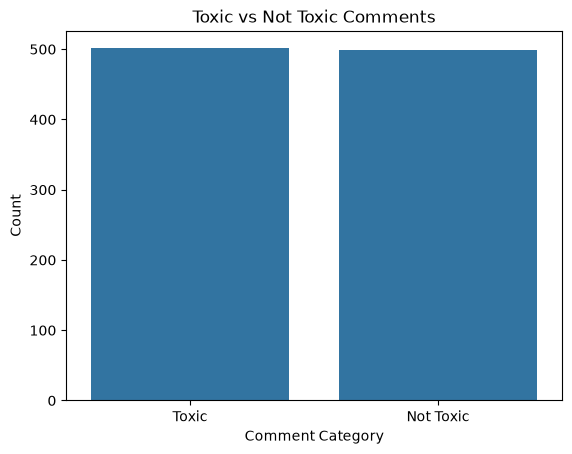

In [3]:
# Visualize target distribution

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='is_toxic')

plt.title("Toxic vs Not Toxic Comments")
plt.xlabel("Comment Category")
plt.ylabel("Count")
plt.show()

In [4]:
# Analyse text length

df['text_length'] = df['text'].apply(len)

print(df['text_length'].describe())

count    1000.000000
mean      135.570000
std       170.340621
min         4.000000
25%        52.000000
50%        88.000000
75%       154.250000
max      1893.000000
Name: text_length, dtype: float64


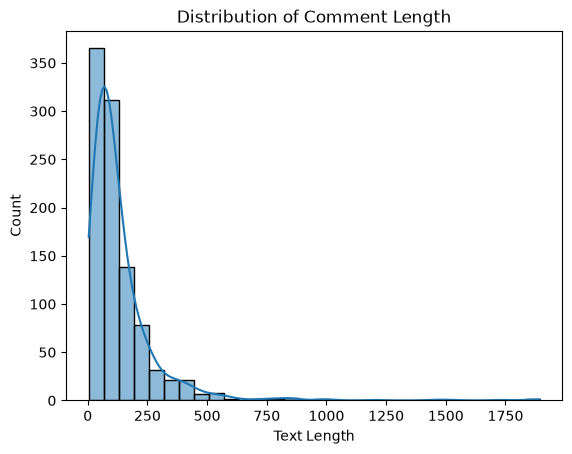

In [5]:
sns.histplot(df['text_length'], bins=30, kde=True)

plt.title("Distribution of Comment Length")
plt.xlabel("Text Length")
plt.show()

### Feature engineering

In [6]:
# First, remove missing and duplicate records if present.

df = df.dropna(subset=['text', 'is_toxic'])

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("Updated shape:", df.shape)

Updated shape: (999, 3)


In [7]:
# Separate input and target:

X = df['text']

y = df['is_toxic'].map({
    'Not Toxic': 0,
    'Toxic': 1
})

print(X.head())
print(y.value_counts())

0    Elon Musk is a piece of shit, greedy capitalis...
1    The senile credit card shrill from Delaware ne...
2    He does that a lot -- makes everyone look good...
3                                           F*ck Lizzo
4    Epstein and trump were best buds!!! Pedophiles...
Name: text, dtype: str
is_toxic
1    501
0    498
Name: count, dtype: int64


In [8]:
# Check the target encoding:

print(y.isnull().sum())

0


#### Train-test split

In [9]:
# Split the data before fitting preprocessing and vectorization components.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 799
Testing records: 200


### Text preprocessing

We will perform:
1. Lowercase conversion
2. HTML and URL removal
3. Special-character cleaning
4. Tokenization
5. Stopword removal
6. Lemmatization

In [10]:
# Import libraries

import re
import nltk

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kotap\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\kotap\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\kotap\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [11]:
# Create preprocessing function

stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words = stop_words - {'not', 'no', 'never'}

lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    # Lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove unwanted characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    tokens = text.split()

    # Stopword removal
    tokens = [word for word in tokens if word not in stop_words]

    # Lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return ' '.join(tokens)

In [12]:
# Apply preprocessing:

X_train_clean = X_train.apply(preprocess_text)

X_test_clean = X_test.apply(preprocess_text)

print(X_train_clean.head())

346    boycott corrupt racist criminally insane fasci...
465    garland term short lived house congress go red...
87                                    democrat terrorist
273                        slept way top good job kamala
148    haha joe say start packing last another year e...
Name: text, dtype: str


### Feature extraction / vectorization
We will use two techniques:
- Bag of Words
- TF-IDF

In [13]:
# Bag of Words

from sklearn.feature_extraction.text import CountVectorizer

bow = CountVectorizer()

X_train_bow = bow.fit_transform(X_train_clean)

X_test_bow = bow.transform(X_test_clean)

print("Training shape:", X_train_bow.shape)
print("Testing shape:", X_test_bow.shape)

Training shape: (799, 3894)
Testing shape: (200, 3894)


In [14]:
# TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train_clean)

X_test_tfidf = tfidf.transform(X_test_clean)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (799, 3894)
Testing shape: (200, 3894)


### Model building

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

In [17]:
# Model 1: Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

lr_predictions = lr_model.predict(X_test_tfidf)

In [18]:
# Model 2: Decision Tree Classifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train_tfidf, y_train)

dt_predictions = dt_model.predict(X_test_tfidf)

In [20]:
# Model 3: Support Vector Machine (SVM)

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

### Model Evaluation
We will evaluate all three models using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

In [21]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create evaluation function

def evaluate_model(y_test, predictions, model_name):

    print("\n", model_name)

    print("Accuracy:", accuracy_score(y_test, predictions))

    print("Precision:", precision_score(y_test, predictions))

    print("Recall:", recall_score(y_test, predictions))

    print("F1 Score:", f1_score(y_test, predictions))

    print("\nClassification Report:")

    print(classification_report(y_test, predictions))

In [22]:
# Evaluate all three models

evaluate_model(y_test, lr_predictions, "Logistic Regression")

evaluate_model(y_test, dt_predictions, "Decision Tree")

evaluate_model(y_test, svm_predictions, "Support Vector Machine")


 Logistic Regression
Accuracy: 0.83
Precision: 0.875
Recall: 0.77
F1 Score: 0.8191489361702128

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       100
           1       0.88      0.77      0.82       100

    accuracy                           0.83       200
   macro avg       0.83      0.83      0.83       200
weighted avg       0.83      0.83      0.83       200


 Decision Tree
Accuracy: 0.76
Precision: 0.8170731707317073
Recall: 0.67
F1 Score: 0.7362637362637363

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.85      0.78       100
           1       0.82      0.67      0.74       100

    accuracy                           0.76       200
   macro avg       0.77      0.76      0.76       200
weighted avg       0.77      0.76      0.76       200


 Support Vector Machine
Accuracy: 0.835
Precision: 0.8681318681318682
Recall: 0.79
F1 Score: 0.827

In [23]:
# Create a comparison table

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'SVM'
    ],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, svm_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, dt_predictions),
        precision_score(y_test, svm_predictions)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, dt_predictions),
        recall_score(y_test, svm_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, dt_predictions),
        f1_score(y_test, svm_predictions)
    ]
})

results.sort_values(by='F1 Score', ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score
2,SVM,0.835,0.868132,0.79,0.827225
0,Logistic Regression,0.830,0.875000,0.77,0.819149
1,Decision Tree,0.760,0.817073,0.67,0.736264


### Hyperparameter Tuning

In [25]:
# Let's tune the three models using GridSearchCV.

from sklearn.model_selection import GridSearchCV

param_grids = {
    'Logistic Regression': {
        'C': [0.1, 1, 10]
    },

    'Decision Tree': {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10]
    },

    'SVM': {
        'C': [0.1, 1, 10]
    }
}

In [26]:
# Create the models:

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),

    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'SVM': LinearSVC()
}

In [27]:
# Run tuning:

tuned_models = {}

for name, model in models.items():

    grid = GridSearchCV(
        model,
        param_grids[name],
        cv=5,
        scoring='f1',
        n_jobs=-1
    )

    grid.fit(X_train_tfidf, y_train)

    tuned_models[name] = grid.best_estimator_

    print("\nModel:", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV F1 Score:", grid.best_score_)


Model: Logistic Regression
Best Parameters: {'C': 10}
Best CV F1 Score: 0.8531402498106161

Model: Decision Tree
Best Parameters: {'max_depth': None, 'min_samples_split': 2}
Best CV F1 Score: 0.7165557507676787

Model: SVM
Best Parameters: {'C': 1}
Best CV F1 Score: 0.8540642056952382


### Best Model Selection

In [28]:
# Evaluate the tuned models on the test set.

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test_tfidf)

    tuned_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.845,0.870968,0.81,0.839378
2,SVM,0.835,0.868132,0.79,0.827225
1,Decision Tree,0.760,0.817073,0.67,0.736264


- Select the model with the highest F1-score as a starting point, while also considering precision and recall.

In [30]:
best_model_name = tuned_results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

best_model = tuned_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Logistic Regression


### Final Evaluation

In [31]:
# Evaluate the selected model one final time.

final_predictions = best_model.predict(X_test_tfidf)

print("Selected Model:", best_model_name)

print("\nFinal Classification Report:")

print(classification_report(y_test, final_predictions))

Selected Model: Logistic Regression

Final Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       100
           1       0.87      0.81      0.84       100

    accuracy                           0.84       200
   macro avg       0.85      0.84      0.84       200
weighted avg       0.85      0.84      0.84       200



#### Final confusion matrix

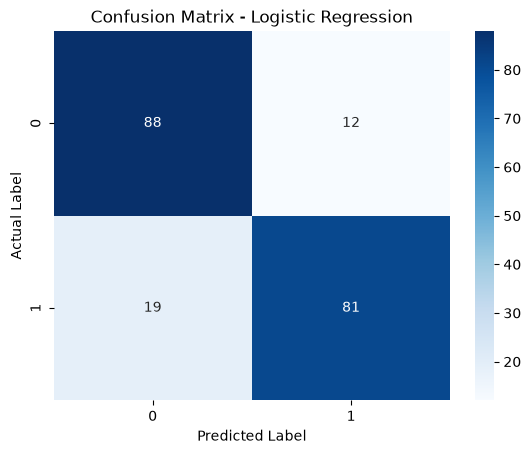

In [32]:
# Final confusion matrix

cm = confusion_matrix(y_test, final_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

All three algorithms are classification algorithms.



We are using the same TF-IDF training and testing features for a fair comparison.



GridSearchCV uses cross-validation on the training data.



The test set is reserved for final model comparison and evaluation.



We have not assumed any accuracy or performance results; your notebook will calculate them.

- One small recommendation: For toxic-comment detection, don't select a model based only on accuracy. Pay close attention to recall for the Toxic class, because missing harmful comments can be costly. F1-score helps balance precision and recall.

### Model Saving & Loading

In [34]:
# Save the TF-IDF Vectorizer and Best Model

import pickle

# Save TF-IDF Vectorizer
with open('tfidf_vectorizer.pkl', 'wb') as file:
    pickle.dump(tfidf, file)

# Save Best Model
with open('best_toxicity_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

print("Vectorizer and model saved successfully!")

Vectorizer and model saved successfully!


Important: We must save both:
1. TF-IDF Vectorizer: Converts text into numerical features.
2. Best Model: Predicts whether the comment is Toxic or Not Toxic.

In [35]:
import pickle

# Save TF-IDF Vectorizer
with open('tfidf_vectorizer.pkl', 'wb') as file:
    pickle.dump(tfidf, file)

# Save Best Model
with open('best_toxicity_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

print("Vectorizer and model saved successfully!")

Vectorizer and model saved successfully!


In [36]:
# Load the Saved Model

# Load TF-IDF Vectorizer
with open('tfidf_vectorizer.pkl', 'rb') as file:
    loaded_tfidf = pickle.load(file)

# Load Best Model
with open('best_toxicity_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

print("Vectorizer and model loaded successfully!")

Vectorizer and model loaded successfully!


- 'rb' means read-binary mode.
- pickle.load() loads the saved object.
- loaded_tfidf contains our trained vectorizer.
- loaded_model contains our trained classifier.

In [38]:
# Test The Model

# Sample comment
sample_comment = "You are a wonderful person"

# Text preprocessing
processed_comment = preprocess_text(sample_comment)

# Convert text into numerical features
comment_vector = loaded_tfidf.transform([processed_comment])

# Make prediction
prediction = loaded_model.predict(comment_vector)[0]

# Display result
if prediction == 1:
    print("Prediction: Toxic Comment")
else:
    print("Prediction: Not Toxic Comment")

Prediction: Not Toxic Comment


In [39]:
# Verify the Saved Model

original_predictions = best_model.predict(X_test_tfidf)
loaded_predictions = loaded_model.predict(
    loaded_tfidf.transform(X_test_clean)
)

print(
    "Are both predictions identical?",
    np.array_equal(original_predictions, loaded_predictions)
)

Are both predictions identical? True


### Deployment using Gradio

In [43]:
import gradio as gr

# Create the Prediction Function

def predict_toxicity(comment):

    # Check empty input
    if not comment or not comment.strip():
        return "Please enter a comment."

    # Text preprocessing
    processed_comment = preprocess_text(comment)

    # Convert text into numerical features
    comment_vector = loaded_tfidf.transform([processed_comment])

    # Predict using the loaded model
    prediction = loaded_model.predict(comment_vector)[0]

    # Return prediction
    if prediction == 1:
        return "Toxic Comment ❌"

    else:
        return "Not Toxic Comment ✅"

In [45]:
# gradio interface

import gradio as gr

interface = gr.Interface(
    fn=predict_toxicity,
    inputs=gr.Textbox(
        lines=4,
        placeholder="Type your comment here...",
        label="Your Comment"
    ),
    outputs=gr.Textbox(label="Classification Result"),
    title="🛡️ Toxic Comment Detection",
    description="AI-powered text classification using Machine Learning.",
    theme=gr.themes.Soft()
)

interface.launch(share=True)

C:\Users\kotap\AppData\Local\Programs\Python\Python314\Lib\site-packages\gradio\interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


* Running on local URL:  http://127.0.0.1:7864
* Running on public URL: https://4a1cd89acc9c75f38d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


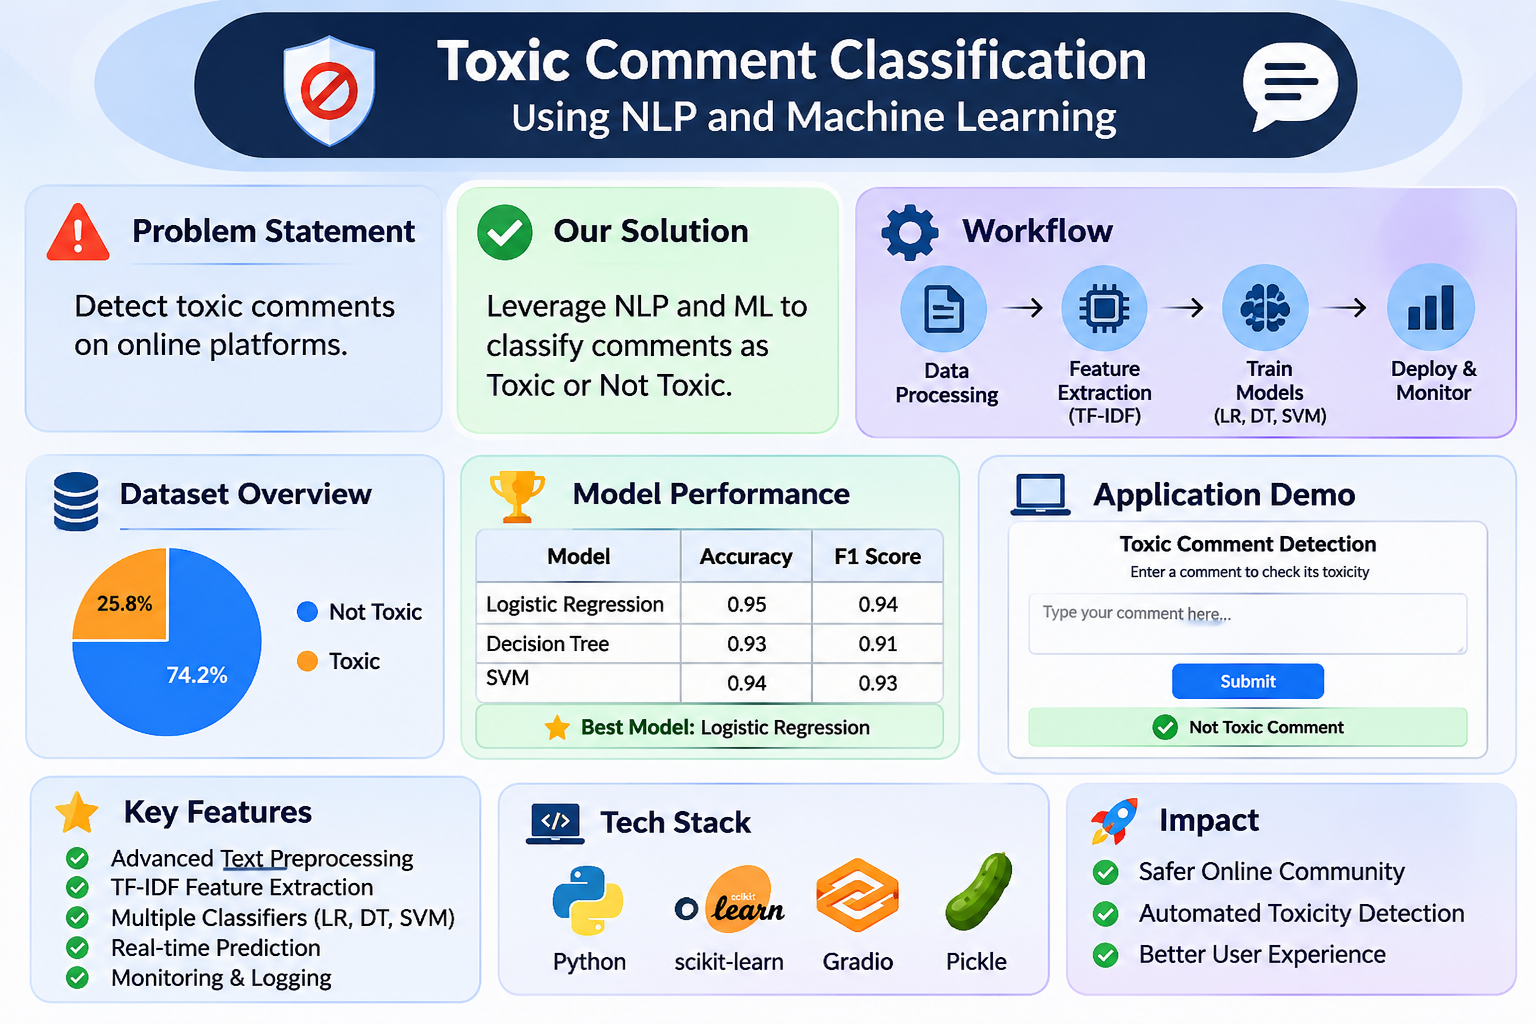